Imports + chargement

In [3]:
from dotenv import load_dotenv
load_dotenv()

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (12, 5)

engine = create_engine(os.environ["DATABASE_URL"].replace("postgres://", "postgresql://", 1))
df_act = pd.read_sql("SELECT * FROM activities_enriched", engine)
df_km = pd.read_sql("SELECT * FROM activities_km", engine)

print(f"df_act : {len(df_act)} sorties, {len(df_act.columns)} colonnes")
print(f"df_km  : {len(df_km)} lignes km")

df_act : 134 sorties, 45 colonnes
df_km  : 808 lignes km


# Notebook 09 : Boxplots pace vs features candidates

Objectif : visualiser, feature par feature, la structure de la relation avec la pace
pour guider le choix des variables de clustering ensuite (notebook 10).

On travaille au **niveau sortie** ici (`df_act`, pace moyenne), parce que c'est ce
niveau qui porte 70 % de la variance (ICC = 0.70). Le clustering sera aussi
par-sortie pour la même raison.

Pour les features catégorielles existantes (day_of_week, month, hour), boxplots classiques.
Pour les features continues, on les discrétise en bins et on fait des boxplots par bin,
plus un scatter pour voir la forme de la relation.

Filtres + variables candidates

In [4]:
# Même filtres que les notebooks de modélisation
dfa = df_act[(df_act["distance_km"] >= 1) & (df_act["distance_km"] < 30)].copy()
print(f"n sorties après filtres : {len(dfa)}")

# Features candidates à investiguer
features_continues = [
    "distance_km", "elev_per_km", "weather_temperature", "weather_humidity",
    "pace_last_5_mean", "pr_count", "pause_ratio", "vol_7d_km", "vol_28d_km",
    "acwr_7_28", "days_since_last"
]
features_cat = ["day_of_week", "month", "hour"]

print(f"\n{len(features_continues)} features continues + {len(features_cat)} catégorielles")

n sorties après filtres : 125

11 features continues + 3 catégorielles


Boxplots features continues (binnées)

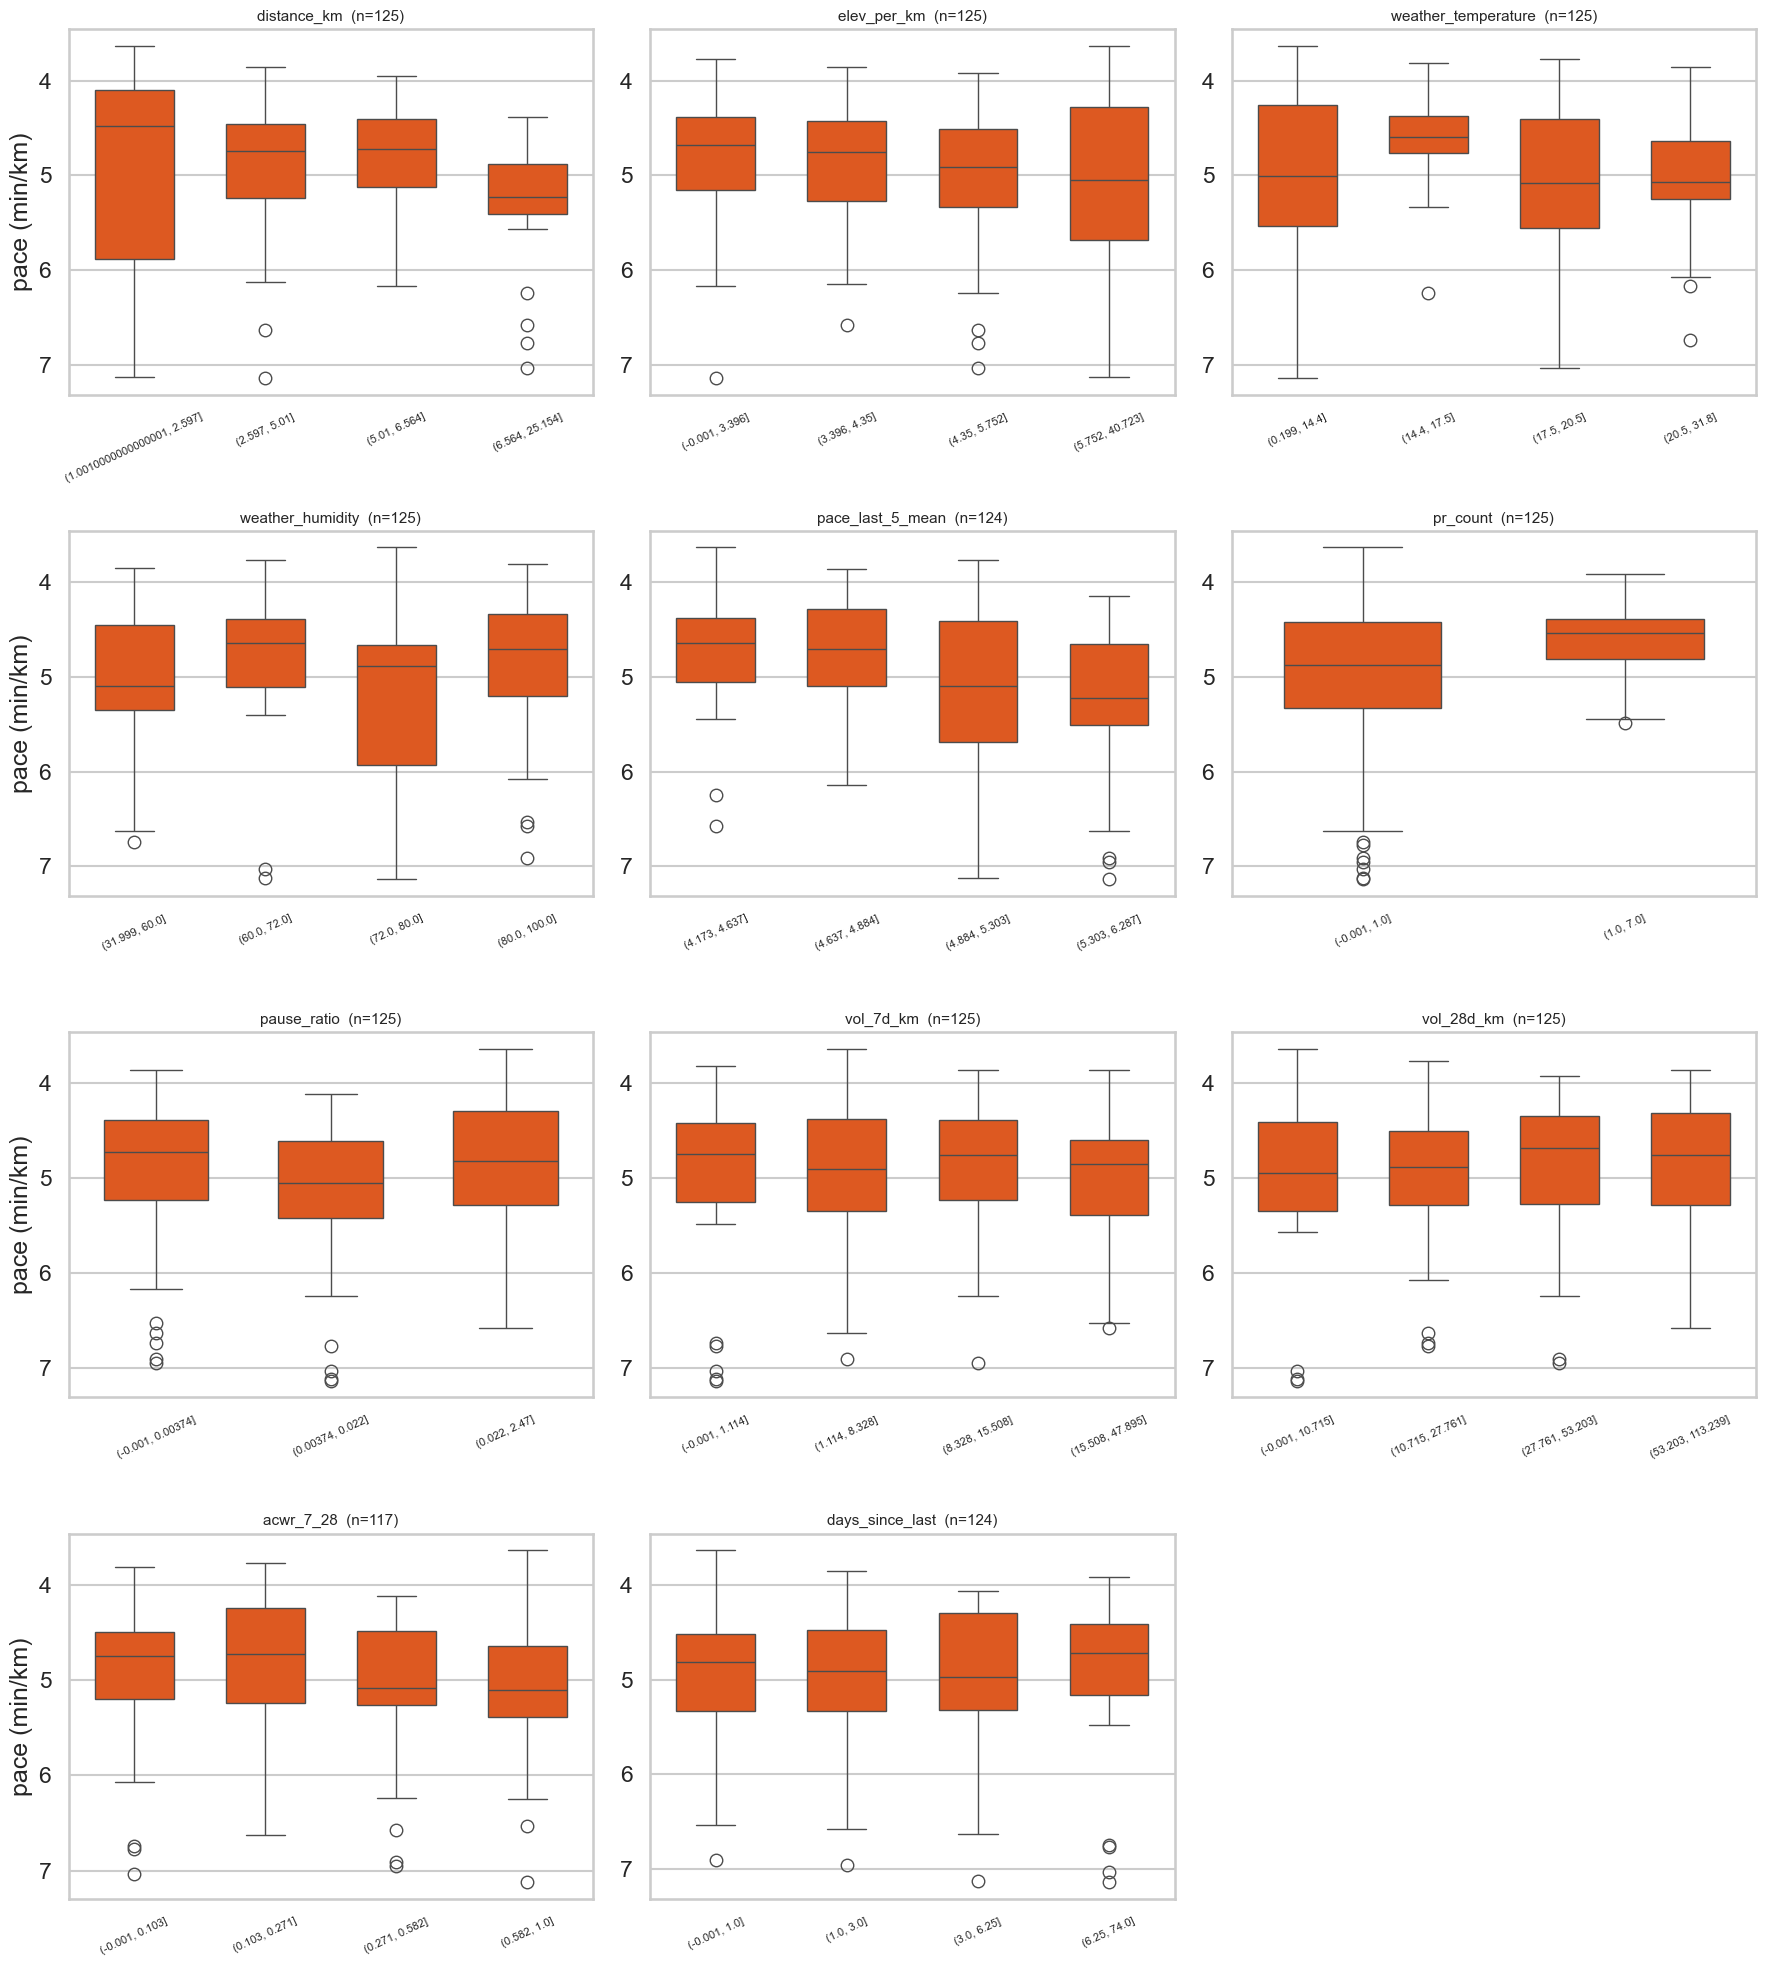

In [5]:
# Discrétisation en quartiles pour chaque feature continue
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, feat in enumerate(features_continues):
    ax = axes[i]
    data = dfa.dropna(subset=[feat, "pace_min_km"]).copy()
    if len(data) < 20:
        ax.text(0.5, 0.5, f"n={len(data)} trop faible", ha="center", va="center")
        ax.set_title(feat)
        continue
    
    # Bins par quartiles
    try:
        data["bin"] = pd.qcut(data[feat], q=4, duplicates="drop")
    except ValueError:
        data["bin"] = pd.cut(data[feat], bins=4)
    
    sns.boxplot(data=data, x="bin", y="pace_min_km", ax=ax, color="#FC4C02", width=0.6)
    ax.set_title(f"{feat}  (n={len(data)})", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("pace (min/km)" if i % 3 == 0 else "")
    ax.tick_params(axis="x", rotation=25, labelsize=8)
    ax.invert_yaxis()  # pace plus rapide = en haut

# Désactive les axes vides
for j in range(len(features_continues), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig("../docs/figures/09_boxplots_continues.png", dpi=120, bbox_inches="tight")
plt.show()

Boxplots features catégorielles

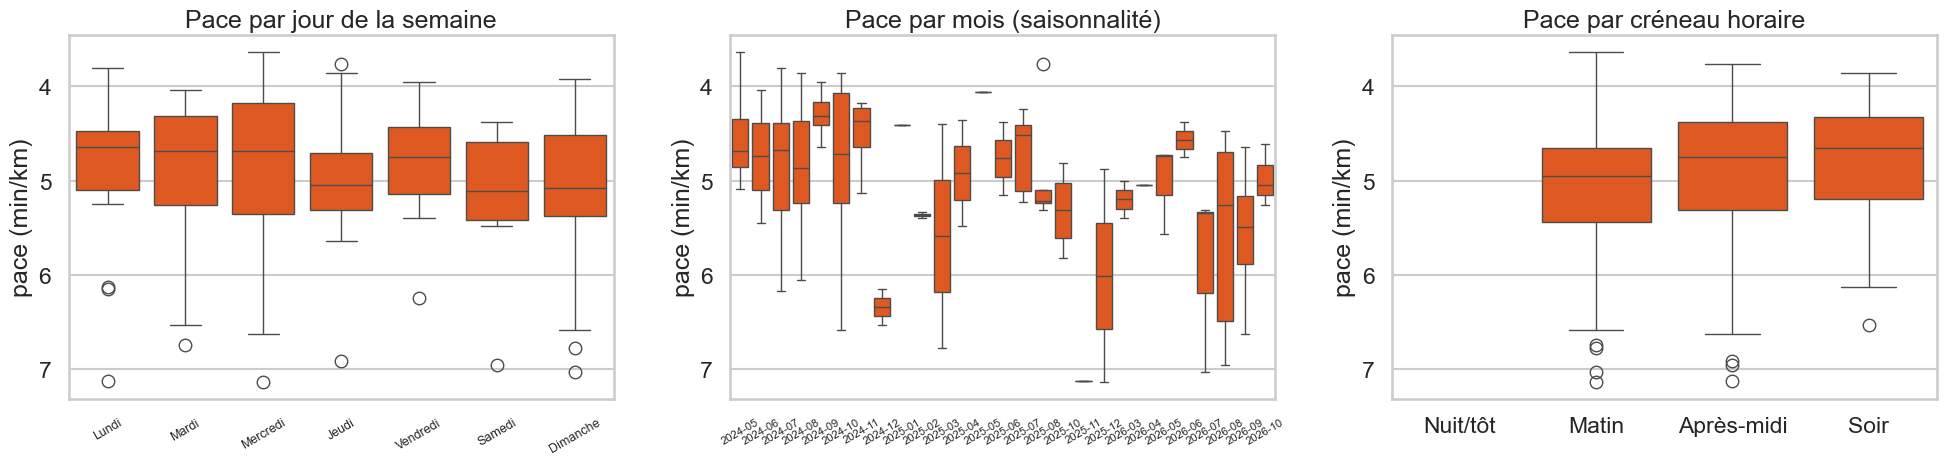

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Day of week
order_dow = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
sns.boxplot(data=dfa, x="day_of_week", y="pace_min_km", order=order_dow,
            ax=axes[0], color="#FC4C02")
axes[0].set_title("Pace par jour de la semaine")
axes[0].tick_params(axis="x", rotation=30, labelsize=9)
axes[0].invert_yaxis()

# Mois
sns.boxplot(data=dfa, x="month", y="pace_min_km", ax=axes[1], color="#FC4C02")
axes[1].set_title("Pace par mois (saisonnalité)")
axes[1].tick_params(axis="x", rotation=30, labelsize=8)
axes[1].invert_yaxis()

# Heure (binnée)
dfa["hour_bin"] = pd.cut(dfa["hour"], bins=[0, 6, 12, 20, 24],
                         labels=["Nuit/tôt", "Matin", "Après-midi", "Soir"])
sns.boxplot(data=dfa.dropna(subset=["hour_bin"]), x="hour_bin", y="pace_min_km",
            ax=axes[2], color="#FC4C02")
axes[2].set_title("Pace par créneau horaire")
axes[2].invert_yaxis()

for ax in axes:
    ax.set_ylabel("pace (min/km)")
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig("../docs/figures/09_boxplots_categorielles.png", dpi=120, bbox_inches="tight")
plt.show()

Scatter continus pour voir la forme (pas que les quartiles)

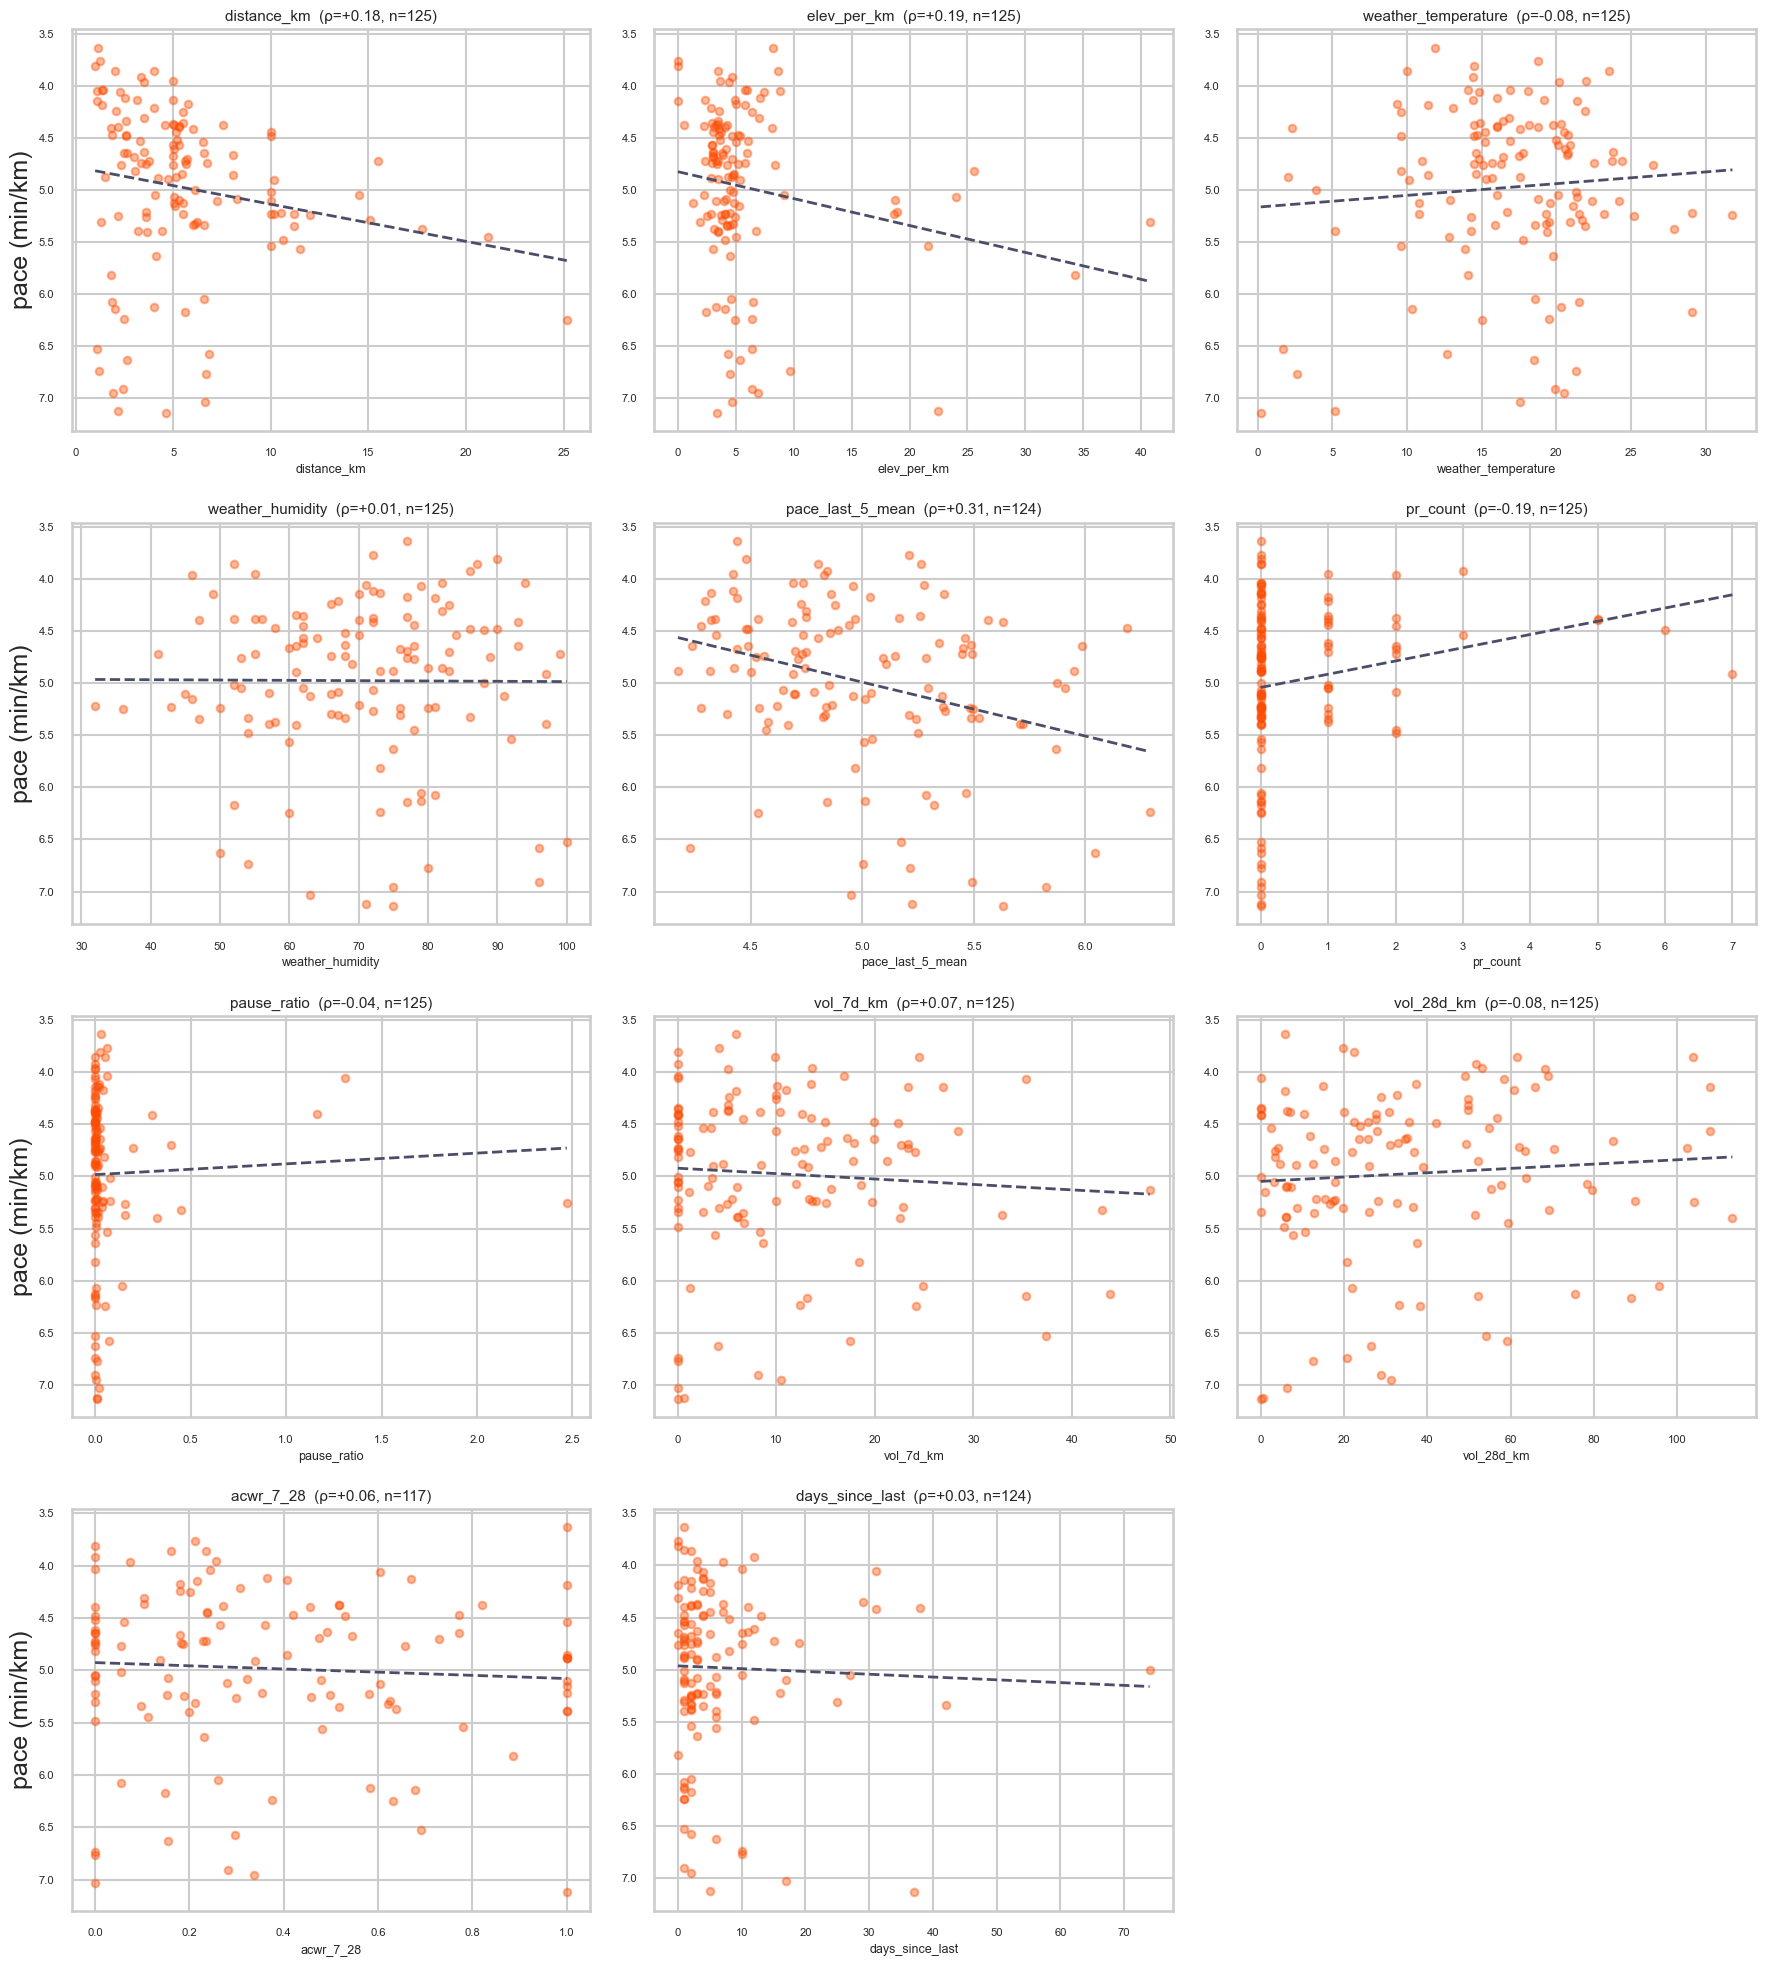

In [11]:
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, feat in enumerate(features_continues):
    ax = axes[i]
    data = dfa.dropna(subset=[feat, "pace_min_km"])
    if len(data) < 10:
        continue
    
    ax.scatter(data[feat], data["pace_min_km"], alpha=0.4, s=30, color="#FC4C02")
    
    # Trendline linéaire + corrélation
    if data[feat].nunique() > 2:
        z = np.polyfit(data[feat], data["pace_min_km"], 1)
        xgrid = np.linspace(data[feat].min(), data[feat].max(), 50)
        ax.plot(xgrid, np.polyval(z, xgrid), color="#4A4E69", lw=2, linestyle="--")
        corr = data[feat].corr(data["pace_min_km"])
        ax.set_title(f"{feat}  (ρ={corr:+.2f}, n={len(data)})", fontsize=11)
    else:
        ax.set_title(f"{feat}  (n={len(data)})", fontsize=11)
    
    ax.set_xlabel(feat, fontsize=9)
    ax.set_ylabel("pace (min/km)" if i % 3 == 0 else "")
    ax.invert_yaxis()
    ax.tick_params(axis="both", labelsize=8)

for j in range(len(features_continues), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig("../docs/figures/09_scatter_pace_vs_features.png", dpi=120, bbox_inches="tight")
plt.show()

Synthèse des corrélations (tableau)

In [12]:
corrs = []
for feat in features_continues:
    data = dfa.dropna(subset=[feat, "pace_min_km"])
    if len(data) < 10 or data[feat].nunique() < 3:
        continue
    r = data[feat].corr(data["pace_min_km"])
    rs = data[feat].corr(data["pace_min_km"], method="spearman")
    corrs.append({"feature": feat, "n": len(data), "pearson": r, "spearman": rs,
                  "|pearson|": abs(r)})

df_corr = pd.DataFrame(corrs).sort_values("|pearson|", ascending=False).reset_index(drop=True)
print("Corrélations pace vs features (triées par |pearson|) :\n")
print(df_corr.to_string(index=False))

Corrélations pace vs features (triées par |pearson|) :

            feature   n   pearson  spearman  |pearson|
   pace_last_5_mean 124  0.312492  0.303159   0.312492
        elev_per_km 125  0.194940  0.158515   0.194940
           pr_count 125 -0.190215 -0.206654   0.190215
        distance_km 125  0.181132  0.285686   0.181132
weather_temperature 125 -0.081483  0.048348   0.081483
         vol_28d_km 125 -0.075557 -0.074907   0.075557
          vol_7d_km 125  0.070055  0.056421   0.070055
          acwr_7_28 117  0.062787  0.095312   0.062787
        pause_ratio 125 -0.035860  0.096100   0.035860
    days_since_last 124  0.034570 -0.014580   0.034570
   weather_humidity 125  0.005592 -0.052916   0.005592


In [13]:
# --- Proxy ensoleillement : élévation solaire géométrique au moment de la sortie ---
import numpy as np
import pandas as pd

LAT_COMPIEGNE = 49.4179  # degrés nord
LON_COMPIEGNE = 2.8260

def solar_elevation(dt_utc, lat_deg=LAT_COMPIEGNE, lon_deg=LON_COMPIEGNE):
    """Élévation solaire en degrés au-dessus de l'horizon.
    Négatif = soleil couché.
    Approximation NOAA (précision ~0.1° suffisante pour un proxy).
    """
    dt_utc = pd.to_datetime(dt_utc, utc=True)
    doy = dt_utc.timetuple().tm_yday
    hour_utc = dt_utc.hour + dt_utc.minute / 60 + dt_utc.second / 3600
    
    # Déclinaison solaire (approx)
    gamma = 2 * np.pi / 365 * (doy - 1 + (hour_utc - 12) / 24)
    decl = (0.006918 - 0.399912 * np.cos(gamma) + 0.070257 * np.sin(gamma)
            - 0.006758 * np.cos(2 * gamma) + 0.000907 * np.sin(2 * gamma))
    
    # Angle horaire (heure solaire locale approchée via longitude)
    solar_hour = hour_utc + lon_deg / 15
    hour_angle = np.radians((solar_hour - 12) * 15)
    
    lat_rad = np.radians(lat_deg)
    sin_elev = (np.sin(lat_rad) * np.sin(decl)
                + np.cos(lat_rad) * np.cos(decl) * np.cos(hour_angle))
    return np.degrees(np.arcsin(np.clip(sin_elev, -1, 1)))

# `start_date_local` est en UTC d'après le dump
dfa["solar_elev_deg"] = dfa["start_date_local"].apply(solar_elevation)
# Proxy "chauffe soleil" : positif si soleil au-dessus de l'horizon, sinon 0
dfa["sun_load"] = dfa["solar_elev_deg"].clip(lower=0)
# Interaction T x sun_load : "T° ressentie par exposition solaire"
dfa["T_x_sun"] = dfa["weather_temperature"] * dfa["sun_load"] / 100  # /100 pour échelle

print(dfa[["start_date_local", "hour", "month", "weather_temperature",
           "solar_elev_deg", "sun_load", "T_x_sun"]].head(10).to_string(index=False))

# Vérif ton exemple : 25°C à 22h en été vs 25°C à 14h en mai
exemples = pd.DataFrame({
    "start_date_local": ["2026-07-15 22:00+02:00", "2026-05-15 14:00+02:00"],
    "label": ["25°C à 22h en juillet", "25°C à 14h en mai"]
})
exemples["start_date_local"] = pd.to_datetime(exemples["start_date_local"], utc=True)
exemples["solar_elev"] = exemples["start_date_local"].apply(solar_elevation)
print("\n--- Vérification sur ton exemple ---")
print(exemples.to_string(index=False))

         start_date_local  hour   month  weather_temperature  solar_elev_deg  sun_load   T_x_sun
2024-05-06 18:15:20+00:00    18 2024-05                 16.4        8.463129  8.463129  1.387953
2024-05-07 12:19:08+00:00    12 2024-05                 16.9       56.995915 56.995915  9.632310
2024-05-08 11:38:29+00:00    11 2024-05                 11.9       57.769293 57.769293  6.874546
2024-05-08 22:09:44+00:00    22 2024-05                 11.4      -19.704373  0.000000  0.000000
2024-05-09 12:32:48+00:00    12 2024-05                 15.7       56.885767 56.885767  8.931065
2024-05-10 11:06:23+00:00    11 2024-05                 17.6       57.216180 57.216180 10.070048
2024-05-11 07:49:28+00:00     7 2024-05                 11.4       33.069243 33.069243  3.769894
2024-05-15 10:40:58+00:00    10 2024-05                 14.7       56.654646 56.654646  8.328233
2024-05-15 22:06:17+00:00    22 2024-05                 14.6      -17.835893  0.000000  0.000000
2024-05-16 11:06:13+00:00    1

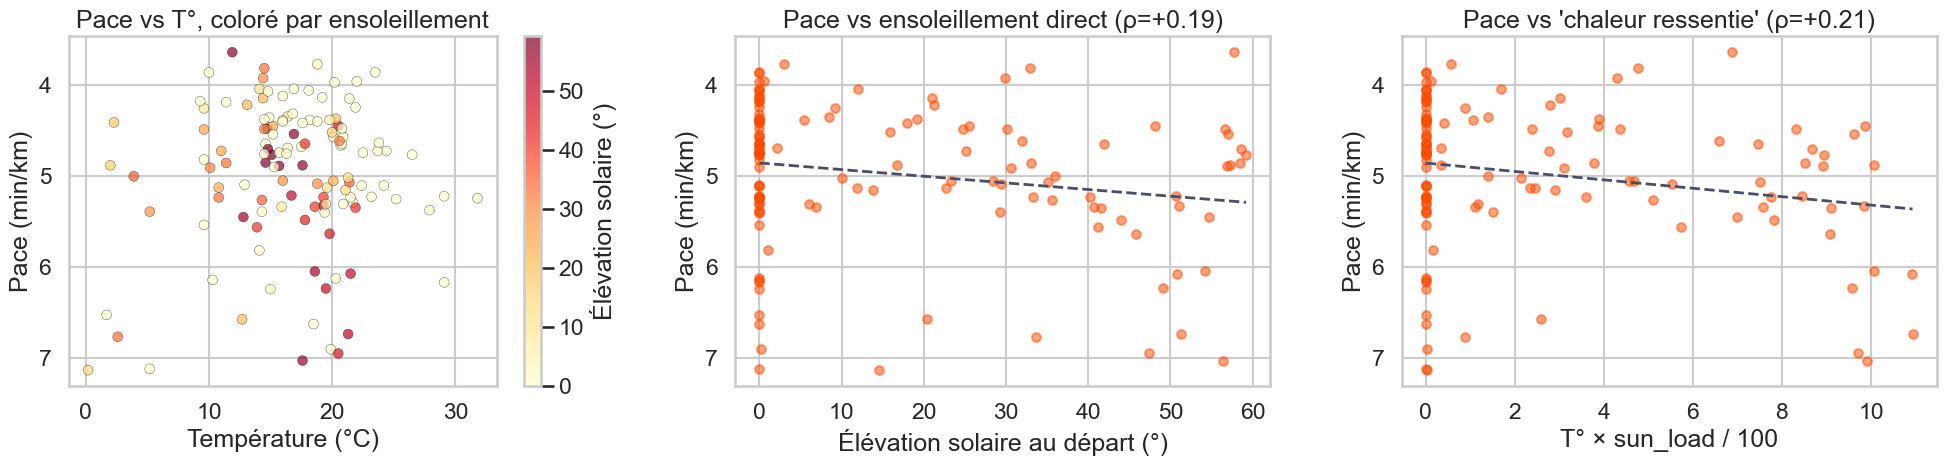

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Scatter pace vs T° coloré par sun_load
sc = axes[0].scatter(dfa["weather_temperature"], dfa["pace_min_km"],
                     c=dfa["sun_load"], cmap="YlOrRd", s=50, alpha=0.7,
                     edgecolors="black", linewidth=0.3)
plt.colorbar(sc, ax=axes[0], label="Élévation solaire (°)")
axes[0].set_xlabel("Température (°C)")
axes[0].set_ylabel("Pace (min/km)")
axes[0].set_title("Pace vs T°, coloré par ensoleillement")
axes[0].invert_yaxis()

# 2. Scatter pace vs sun_load directement
axes[1].scatter(dfa["sun_load"], dfa["pace_min_km"], alpha=0.5, s=40, color="#FC4C02")
if dfa["sun_load"].nunique() > 2:
    z = np.polyfit(dfa["sun_load"], dfa["pace_min_km"], 1)
    xg = np.linspace(0, dfa["sun_load"].max(), 50)
    axes[1].plot(xg, np.polyval(z, xg), color="#4A4E69", lw=2, ls="--")
corr = dfa["sun_load"].corr(dfa["pace_min_km"])
axes[1].set_xlabel("Élévation solaire au départ (°)")
axes[1].set_ylabel("Pace (min/km)")
axes[1].set_title(f"Pace vs ensoleillement direct (ρ={corr:+.2f})")
axes[1].invert_yaxis()

# 3. Scatter pace vs T x sun_load (variable composite)
axes[2].scatter(dfa["T_x_sun"], dfa["pace_min_km"], alpha=0.5, s=40, color="#FC4C02")
if dfa["T_x_sun"].nunique() > 2:
    z = np.polyfit(dfa["T_x_sun"], dfa["pace_min_km"], 1)
    xg = np.linspace(dfa["T_x_sun"].min(), dfa["T_x_sun"].max(), 50)
    axes[2].plot(xg, np.polyval(z, xg), color="#4A4E69", lw=2, ls="--")
corr2 = dfa["T_x_sun"].corr(dfa["pace_min_km"])
axes[2].set_xlabel("T° × sun_load / 100")
axes[2].set_ylabel("Pace (min/km)")
axes[2].set_title(f"Pace vs 'chaleur ressentie' (ρ={corr2:+.2f})")
axes[2].invert_yaxis()

plt.tight_layout()
plt.savefig("../docs/figures/09_sunshine_proxy.png", dpi=120, bbox_inches="tight")
plt.show()